# DAY5 실습 01 — 산점도와 상관계수 복습

In [ ]:
%pip install -q koreanize-matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from scipy import stats

In [ ]:
import os

from google.colab import drive

drive.mount("/content/drive")
data_folder = "/content/drive/MyDrive/HD-AI/data"
csv_path = os.path.join(data_folder, "ai4i2020.csv")

df = pd.read_csv(csv_path)

data = df.copy()

Mounted at /content/drive


## 데이터와 질문

데이터 파일 : `ai4i2020.csv`
출처 : UCI Machine Learning Repository - [AI4I 2020 Predictive Maintenance Dataset](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset)

한 행은 **운전 기록 1건**이다. 같은 행에 적힌 두 측정값을 **관측쌍** 하나로 본다.

| 원래 열 이름 | 바꾼 이름 | 뜻 | 단위 |
|---|---|---|---|
| Air temperature [K] | `air_temperature_k` | 공기온도 | K (켈빈) |
| Process temperature [K] | `process_temperature_k` | 공정온도 | K |
| Rotational speed [rpm] | `rotational_speed_rpm` | 회전수 | rpm (분당 회전수) |
| Torque [Nm] | `torque_nm` | 토크 | Nm (뉴턴미터) |
| Tool wear [min] | `tool_wear_min` | 공구 마모시간 | 분 |
| Type | `Type` (그대로) | 제품 유형 (L : 저품질, M : 중품질, H : 고품질) | 없음 |

**질문** : 제조 측정값 두 개는 함께 움직이는가? 함께 움직인다면 어떤 방향과 모양인가?

**실습 전제** : AI4I는 제조 예지보전을 학습하도록 만든 합성 데이터다. 관측쌍끼리 서로 독립이라고 가정한다.

In [ ]:
raw = data.rename(columns={"Air temperature [K]": "air_temperature_k",       # 공기온도 (K)
                           "Process temperature [K]": "process_temperature_k",  # 공정온도 (K)
                           "Rotational speed [rpm]": "rotational_speed_rpm",    # 회전수 (rpm)
                           "Torque [Nm]": "torque_nm",                          # 토크 (Nm)
                           "Tool wear [min]": "tool_wear_min"})                 # 공구 마모시간 (분)

numeric_cols = ["air_temperature_k", "process_temperature_k", "rotational_speed_rpm", "torque_nm", "tool_wear_min"]
print("행·열:", raw.shape)
print(raw[numeric_cols].isna().sum())        # 열마다 결측(빈 값) 개수. 상관은 같은 행의 두 값으로 계산하므로 먼저 확인한다

행·열: (10000, 14)
air_temperature_k        0
process_temperature_k    0
rotational_speed_rpm     0
torque_nm                0
tool_wear_min            0
dtype: int64


## 1. 산점도와 상관계수 r

**산점도**는 두 수치형 변수의 값을 가로축(x)과 세로축(y)에 대응시켜, 관측 하나를 좌표평면 위의 점 하나로 나타낸 그래프다. 두 변수 사이의 관계가 어떤 방향 · 강도 · 형태를 갖는지 시각적으로 확인할 때 쓴다.

| 순서 | 기준 | 보는 것 |
|---|---|---|
| 1) | 방향 | 양의 관계인가, 음의 관계인가, 뚜렷한 방향이 없는가 |
| 2) | 강도 | 점들이 직선 주변에 얼마나 모여 있는가 |
| 3) | 형태 | 직선인가, 한 방향으로 휜 곡선인가, U자처럼 방향이 바뀌는가 |
| 4) | 군집 | 서로 다른 조건의 점들이 따로 모여 있는가 |
| 5) | 이상값 | 전체 패턴에서 멀리 떨어진 점이 있는가 |

**상관계수** r은 직선 관계를 −1 ~ 1 사이 숫자 하나로 요약한 값이다. 부호는 방향, 절댓값 |r|은 강도다.

| \|r\| | 0 ~ 0.1 | 0.1 ~ 0.4 | 0.4 ~ 0.7 | 0.7 ~ 1 |
|---|---|---|---|---|
| 강도 | 거의 없음 | 약함 | 보통 | 강함 |

이 구간은 해석을 돕기 위해 널리 쓰는 관례적 기준이며, 분야와 문헌마다 구간이 조금씩 다르다. 같은 r이라도 곡선이나 이상값이 있으면 뜻이 달라지므로 산점도와 함께 읽는다.


| 함수 | 기능 |
|---|---|
| `plt.scatter(x, y, s=점 크기, alpha=투명도)` | 산점도. x와 y는 같은 순서의 두 열을 넣는다 |
| `x.corr(y)` | 두 열의 피어슨 상관계수 r |

공식 문서 : [NIST : Scatter Plot](https://www.itl.nist.gov/div898/handbook/eda/section3/scatterp.htm) · [matplotlib.pyplot.scatter](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html) · [pandas.Series.corr](https://pandas.pydata.org/docs/reference/api/pandas.Series.corr.html)

관측쌍 수: 10000
r: 0.876


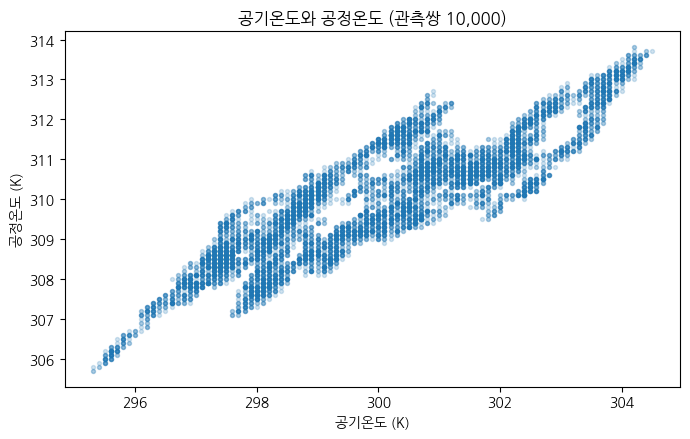

In [ ]:
# [예제] 공기온도와 공정온도의 산점도를 그리고 r 을 구한다
temp_pair = raw[["air_temperature_k", "process_temperature_k"]].dropna()
#   두 열을 함께 뽑은 뒤 dropna : 둘 중 하나라도 빈 행을 통째로 뺀다 → 관측쌍이 깨지지 않는다
x = temp_pair["air_temperature_k"]
y = temp_pair["process_temperature_k"]
print("관측쌍 수:", len(temp_pair))
print("r:", round(x.corr(y), 3))

plt.figure(figsize=(7, 4.5))
plt.scatter(x, y, s=8, alpha=0.2)
#   s=8 : 점 크기, alpha=0.2 : 투명도(0 ~ 1). 점이 10,000개라 겹치는 곳이 진하게 보이도록 투명하게 그린다
plt.xlabel("공기온도 (K)")
plt.ylabel("공정온도 (K)")
plt.title("공기온도와 공정온도 (관측쌍 10,000)")
plt.tight_layout()
plt.show()

# [결과]
# - 관측쌍 10,000, r = 0.876
# - 1) 방향 : 오른쪽 위로 올라간다 → 양의 관계 / 2) 강도 : |r| = 0.876, 직선 띠에 모여 있어 강함
# - 3) 형태 : 직선 / 4) 군집 : 여러 줄의 띠가 보인다 / 5) 이상값 : 크게 벗어난 점은 보이지 않는다
# - 공기온도가 높은 기록에서 공정온도도 높은 강한 양의 직선 관계다

## 2. 관계의 형태 : 직선과 곡선

상관계수 r은 직선 관계를 요약하는 값이라, 점들이 휘어 있으면 직선 부분만 담는다. 같은 "강함"이라도 모양은 다를 수 있으므로 산점도로 확인한다.

| 형태 | 상관계수 하나로 요약하면 |
|---|---|
| 직선 | 잘 요약된다 |
| 한 방향으로 휜 곡선 | 직선 부분만 담긴다 → 스피어만 상관계수도 함께 본다 |
| U자 (방향이 바뀜) | 뚜렷한 U자 관계가 있어도 0에 가깝게 나올 수 있다 |

관측쌍 수: 10000 / r: -0.875


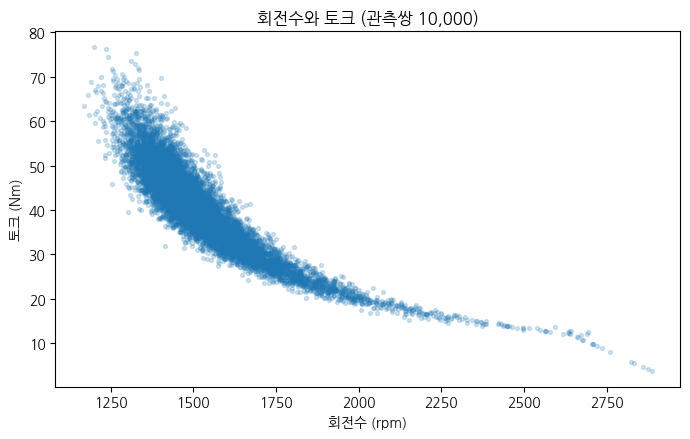

In [ ]:
# [예제] 회전수와 토크의 산점도에서 방향과 형태를 읽는다
speed_pair = raw[["rotational_speed_rpm", "torque_nm"]].dropna()
speed = speed_pair["rotational_speed_rpm"]
torque = speed_pair["torque_nm"]
print("관측쌍 수:", len(speed_pair), "/ r:", round(speed.corr(torque), 3))

plt.figure(figsize=(7, 4.5))
plt.scatter(speed, torque, s=8, alpha=0.2)
plt.xlabel("회전수 (rpm)")
plt.ylabel("토크 (Nm)")
plt.title("회전수와 토크 (관측쌍 10,000)")
plt.tight_layout()
plt.show()

# [결과]
# - r = −0.875 → 음의 관계, 강함
# - 형태 : 직선이 아니라 완만하게 휜 곡선이다. 회전수가 낮은 구간에서 토크가 급하게 커진다
# - r 은 휜 모양까지 말해 주지 않는다. 그래서 숫자와 산점도를 함께 본다

## 3. 집단으로 나눠 다시 보기 (층화 분석)

**층화 분석**은 전체 관계를 본 뒤, 의미 있는 범주형 기준으로 나누어 같은 관계가 유지되는지 다시 보는 방법이다.
| 함수 | 기능 |
|---|---|
| `표.groupby("집단열")[["열1", "열2"]].corr()` | 집단마다 2 × 2 상관표. 대각선 밖 값이 그 집단의 r이다 |

공식 문서 : [pandas.DataFrame.corr](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html) · [pandas.DataFrame.groupby](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html)

,0
Type,
H,1003
L,6000
M,2997


air_temperature_k  process_temperature_k
Type                                                                
H    air_temperature_k                  1.000                  0.876
     process_temperature_k              0.876                  1.000
L    air_temperature_k                  1.000                  0.873
     process_temperature_k              0.873                  1.000
M    air_temperature_k                  1.000                  0.882
     process_temperature_k              0.882                  1.000

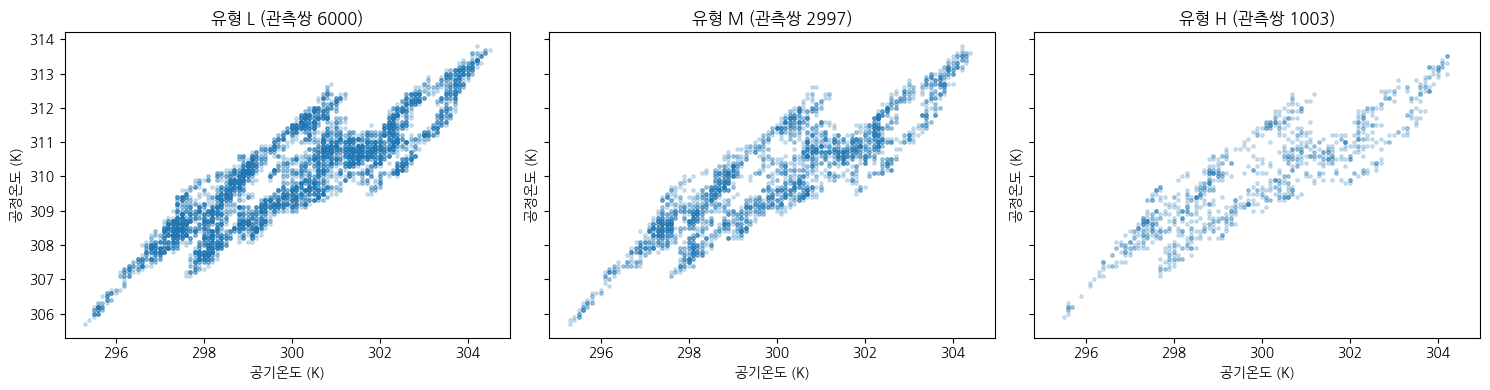

In [ ]:
# [실습]
# 상황 : AI4I 공기온도 · 공정온도도 제품 유형(L · M · H)이 섞인 자료다. 유형별로 나눠도 관계가 같은지 확인한다.
# 제품 유형별 관측쌍 수와 공기온도 · 공정온도의 r 을 구하고, 유형별로 칸을 나눠 산점도를 그린 뒤 전체 r(0.876)과 비교하시오.

# 1) 제품 유형별 관측쌍 수와 상관계수 확인
display(raw.groupby("Type").size())  # 유형별 관측쌍 수(n)

display(
    raw.groupby("Type")[["air_temperature_k", "process_temperature_k"]]
       .corr().round(3)
)  # 유형별 2×2 상관계수 표


# 2) 제품 유형별 산점도 비교
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
# 1행 3열 그래프를 만들고, 비교하기 쉽도록 축 범위를 동일하게 설정한다.

for ax, t in zip(axes, ["L", "M", "H"]):
    sub = raw.loc[raw["Type"] == t]  # 해당 유형의 데이터 선택

    ax.scatter(
        sub["air_temperature_k"],
        sub["process_temperature_k"],
        s=6, alpha=0.2
    )  # 공기온도와 공정온도의 산점도

    ax.set(
        title="유형 " + t + " (관측쌍 " + str(len(sub)) + ")",
        xlabel="공기온도 (K)",
        ylabel="공정온도 (K)"
    )

plt.tight_layout()
plt.show()

# - H 1,003쌍 r = 0.876 / L 6,000쌍 r = 0.873 / M 2,997쌍 r = 0.882
# - 세 칸 모두 같은 범위에 오른쪽 위로 올라가는 직선 띠가 보인다
# - 세 유형 모두 전체 r 0.876 과 비슷한 강한 양의 관계다. 유형을 나눠도 관계가 유지된다

관측쌍 수: 10000 / r: -0.003


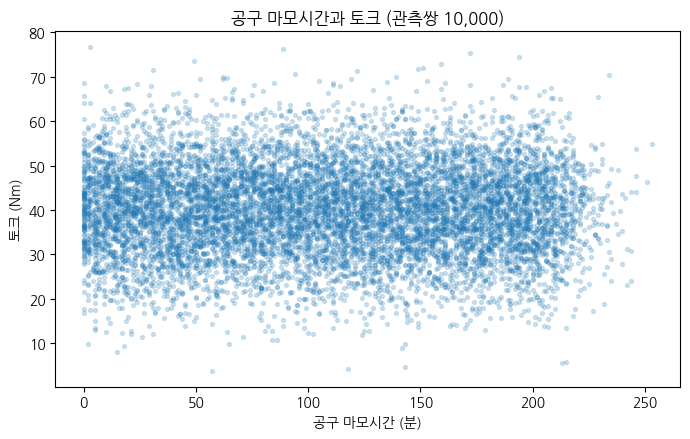

In [ ]:
# [실습]
# 상황 : 공구 마모시간과 토크가 함께 움직이는지 확인한다.
# 공구 마모시간 · 토크 관측쌍을 만들어 산점도를 그리고 r 을 구한 뒤, 방향 · 강도 · 형태 · 군집 · 이상값 순서로 읽으시오.

wear_pair = raw[["tool_wear_min", "torque_nm"]].dropna()
print("관측쌍 수:", len(wear_pair), "/ r:", round(wear_pair["tool_wear_min"].corr(wear_pair["torque_nm"]), 3))

plt.figure(figsize=(7, 4.5))
plt.scatter(wear_pair["tool_wear_min"], wear_pair["torque_nm"], s=8, alpha=0.2)
plt.xlabel("공구 마모시간 (분)")
plt.ylabel("토크 (Nm)")
plt.title("공구 마모시간과 토크 (관측쌍 10,000)")
plt.tight_layout()
plt.show()

# - 관측쌍 10,000, r = −0.003
# - 방향 · 강도 : 뚜렷한 방향이 없고, |r| < 0.1 이라 직선 관계가 거의 없다
# - 형태 : 점이 가로로 넓게 퍼진 띠다. 곡선이나 U자도 보이지 않는다
# - 군집 · 이상값 : 따로 떨어진 무리나 크게 벗어난 점은 보이지 않는다


## 4. 정리

| 순서 | 할 일 | 코드 |
|---|---|---|
| 1) | 두 열을 함께 뽑아 관측쌍을 만든다 | `표[["x열", "y열"]].dropna()` |
| 2) | 산점도를 그려 방향 · 강도 · 형태 · 군집 · 이상값을 읽는다 | `plt.scatter(x, y)` |
| 3) | 상관계수 r로 방향과 강도를 요약한다 | `x.corr(y)` |
| 4) | 의미 있는 집단 기준이 있으면 나눠서 다시 본다 | `표.groupby("집단열")[["열1", "열2"]].corr()` |

### 해석 시 유의점

- 상관계수는 직선 관계만 요약한다. 곡선 · U자 · 군집은 산점도로 확인한다
- 집단이 섞여 있으면 나눠서도 본다. 섞인 채로 구한 r은 강도나 방향이 달라질 수 있다
- 이상값 후보는 지우기 전에 원인을 확인한다
- 함께 움직인다는 것은 관계까지다. 한쪽이 다른 쪽의 원인이라는 뜻은 아니다